<a href="https://colab.research.google.com/github/victormartinezf-droid/deepLearning/blob/main/S08_CNN_Regularization_MNIST_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regularization in Convolutional Neural Networks Using MNIST

**Authors**
- Martínez Falcones Víctor
- Moreira Santos Genoveva
- Sanchez Pinargote Rafael

**Course:** Artificial Intelligence and Deep Learning  
**Activity:** Hands-on CNN Regularization  
**Session:** 8 — 25/10/2026

---

### Execution note
This notebook is designed for **Google Colab** and follows the activity worksheet closely.  
It computes all metrics, plots, tables, analytical answers, and conclusions automatically from the actual run.

The notebook-generation environment did not provide TensorFlow runtime access, so training outputs have **not been fabricated or pre-filled**. Run **Runtime → Run all** in Google Colab to obtain and preserve the real experimental results.


## 1. Objective

The purpose of this experiment is to investigate how regularization affects a Convolutional Neural Network's ability to generalize from training data to unseen MNIST images.

Three models are compared under the same main CNN architecture:

1. **Model A — Baseline CNN**
2. **Model B — CNN with Dropout**
3. **Model C — CNN with Data Augmentation + Dropout**

The comparison focuses on training accuracy, validation accuracy, test accuracy, loss curves, and the **generalization gap**. An optional **Early Stopping** experiment is also included.

### Experimental principle
A model is not considered better only because it achieves higher training accuracy. The important question is whether it maintains good performance on unseen data while avoiding excessive overfitting.


## 2. Environment and Reproducibility

**Purpose:** Load the required libraries and set a fixed random seed to improve reproducibility.

**Important code:** `tf.keras.utils.set_random_seed(42)` controls several sources of randomness used during model initialization and training.


In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, regularizers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Random seed: 42")

TensorFlow version: 2.21.0
Random seed: 42


## 3. MNIST Dataset Preparation

**Purpose:** Load MNIST, normalize pixel values, add the channel dimension, and create the training and validation subsets required by the worksheet.

MNIST contains grayscale handwritten digits from 0 to 9. Each image has size **28 × 28 × 1**.

**Important code:** dividing by `255.0` scales pixel values from `[0, 255]` to `[0, 1]`.


In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixels to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add one grayscale channel
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# Worksheet subsets
x_train_small, y_train_small = x_train[:3000], y_train[:3000]
x_val, y_val = x_train[3000:4000], y_train[3000:4000]

print("Training:", x_train_small.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)
print("Pixel range:", float(x_train_small.min()), "to", float(x_train_small.max()))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training: (3000, 28, 28, 1)
Validation: (1000, 28, 28, 1)
Test: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


### Interpretation

Expected shapes after preprocessing:

- Training: `(3000, 28, 28, 1)`
- Validation: `(1000, 28, 28, 1)`
- Test: `(10000, 28, 28, 1)`

The deliberately small training subset makes overfitting easier to observe, which is useful for studying regularization.


## 4. Data Visualization

**Purpose:** Inspect examples before training to confirm that images and labels are consistent.


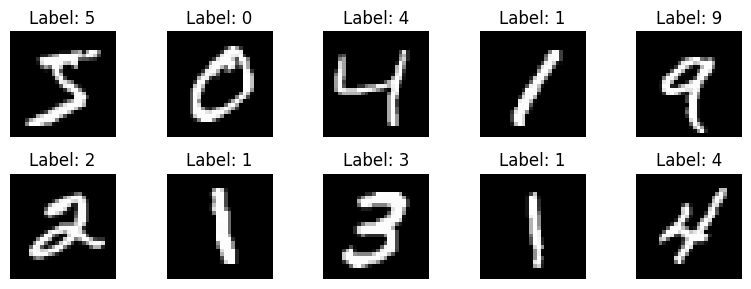

In [3]:
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_small[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train_small[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Interpretation

The images should show handwritten digits with their corresponding labels. This visual check confirms that the preprocessing has not altered the semantic content of the data.


## 5. CNN Architecture

**Purpose:** Define one common CNN-building function so that the three experiments differ only in the regularization strategy being studied.

Architecture:

`Input → Conv2D(32) → MaxPooling → Conv2D(64) → MaxPooling → Flatten → Dense(128) → optional Dropout → Dense(10, Softmax)`

**Important code**
- `Conv2D(..., (3, 3))`: learns local 3 × 3 filters.
- `MaxPooling2D((2, 2))`: reduces spatial resolution.
- `Dropout(rate)`: randomly deactivates eligible activations during training.
- `Dense(10, activation="softmax")`: produces probabilities for the ten digit classes.


In [4]:
def build_cnn(dropout_rate=0.0, use_augmentation=False, l2_strength=0.0):
    model = models.Sequential(name="cnn_model")
    model.add(layers.Input(shape=(28, 28, 1)))

    if use_augmentation:
        model.add(layers.RandomTranslation(0.05, 0.05, name="random_translation"))

    model.add(layers.Conv2D(
        32, (3, 3), activation="relu",
        kernel_regularizer=regularizers.l2(l2_strength),
        name="conv_1"
    ))
    model.add(layers.MaxPooling2D((2, 2), name="pool_1"))

    model.add(layers.Conv2D(
        64, (3, 3), activation="relu",
        kernel_regularizer=regularizers.l2(l2_strength),
        name="conv_2"
    ))
    model.add(layers.MaxPooling2D((2, 2), name="pool_2"))

    model.add(layers.Flatten(name="flatten"))
    model.add(layers.Dense(128, activation="relu", name="dense_128"))

    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate, name="dropout"))

    model.add(layers.Dense(10, activation="softmax", name="output"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

## 6. Models for Comparison

The experiment keeps the main CNN architecture constant.

- **Baseline:** no additional regularization.
- **Dropout:** adds `Dropout(0.4)`.
- **Augmentation + Dropout:** adds small random translations plus `Dropout(0.4)`.

This isolates the effect of the regularization strategies as much as possible.


In [5]:
baseline = build_cnn()
dropout_model = build_cnn(dropout_rate=0.4)
augmented_model = build_cnn(dropout_rate=0.4, use_augmentation=True)

models_to_compare = {
    "Baseline": baseline,
    "Dropout": dropout_model,
    "Augmentation + Dropout": augmented_model
}

for name, model in models_to_compare.items():
    print(f"{name:25s} Parameters: {model.count_params():,}")

Baseline                  Parameters: 225,034
Dropout                   Parameters: 225,034
Augmentation + Dropout    Parameters: 225,034


### Interpretation

The three models should have essentially the same number of trainable parameters. Dropout and random translation alter the **training process**, not the core parameter count of the classifier.

This is important for a fair comparison: a performance difference should not simply come from giving one model a much larger architecture.


## 7. Model Training

**Purpose:** Train all three models under the same conditions.

- Epochs: **10**
- Batch size: **64**
- Same training subset
- Same validation subset

Validation data are used to monitor generalization but do not update model weights.


In [6]:
EPOCHS = 10
BATCH_SIZE = 64

histories = {}

for name, model in models_to_compare.items():
    print("\n" + "=" * 70)
    print("Training:", name)
    print("=" * 70)

    result = model.fit(
        x_train_small,
        y_train_small,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    histories[name] = result.history


Training: Baseline
Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.7097 - loss: 1.0362 - val_accuracy: 0.8970 - val_loss: 0.3116
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9200 - loss: 0.2795 - val_accuracy: 0.9380 - val_loss: 0.1939
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9567 - loss: 0.1657 - val_accuracy: 0.9530 - val_loss: 0.1340
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9697 - loss: 0.1176 - val_accuracy: 0.9650 - val_loss: 0.1068
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9773 - loss: 0.0874 - val_accuracy: 0.9690 - val_loss: 0.0904
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9847 - loss: 0.0643 - val_accuracy: 0.9770 - val_loss: 0.0832
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9897 - loss: 0.0473 - val_accuracy: 0.9740 - val_loss: 0.0809
Epoch 8/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9933 - loss: 0.0351 - val_

### What to observe

During training, compare:

- `accuracy` vs. `val_accuracy`
- `loss` vs. `val_loss`

A widening difference between training and validation performance may indicate overfitting.


## 8. Accuracy Curves

**Purpose:** Compare how well each model learns the training data and how well that learning transfers to validation data.


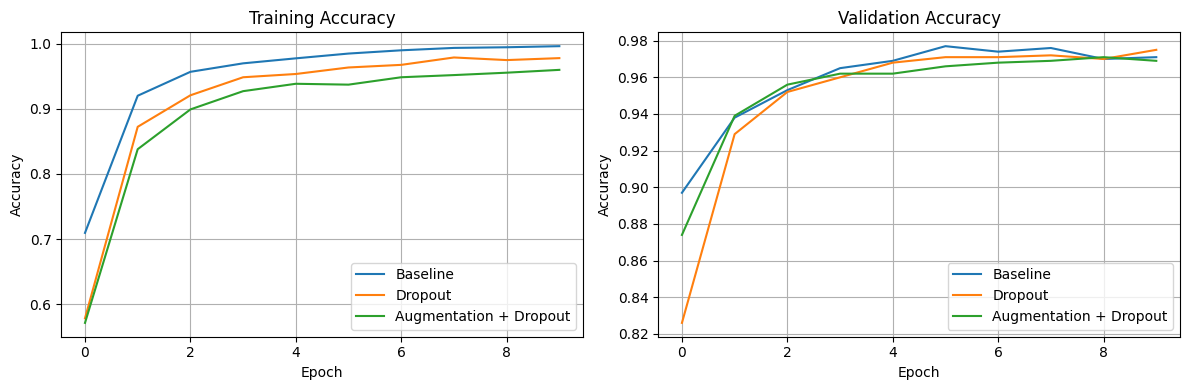

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in histories.items():
    axes[0].plot(history["accuracy"], label=name)
    axes[1].plot(history["val_accuracy"], label=name)

axes[0].set_title("Training Accuracy")
axes[1].set_title("Validation Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Interpretation guide

- A high training accuracy alone is not sufficient evidence of good generalization.
- If training accuracy continues increasing while validation accuracy stops improving or decreases, the model may be overfitting.
- A regularized model may have slightly lower training accuracy but equal or better validation accuracy.


## 9. Loss Curves

**Purpose:** Examine whether optimization on the training set continues while validation performance begins to deteriorate.


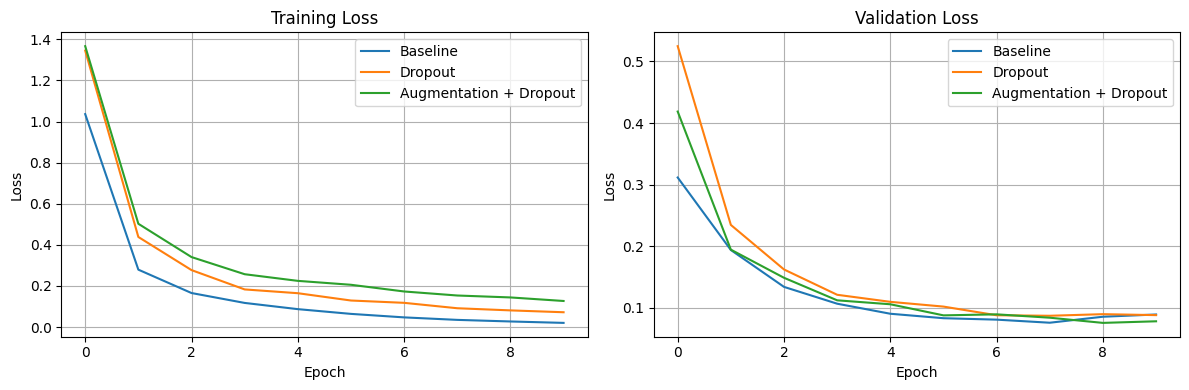

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in histories.items():
    axes[0].plot(history["loss"], label=name)
    axes[1].plot(history["val_loss"], label=name)

axes[0].set_title("Training Loss")
axes[1].set_title("Validation Loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Interpretation guide

A common sign of overfitting is:

- training loss continues to decrease;
- validation loss stops decreasing and begins to increase.

This indicates that additional fitting to the training set is no longer improving generalization.


## 10. Test Evaluation

**Purpose:** Evaluate each trained model on the untouched MNIST test set.

The test set should not be used repeatedly to tune hyperparameters. It is reserved for final evaluation after training and validation-based model development.


In [9]:
test_results = {}

for name, model in models_to_compare.items():
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
    test_results[name] = {
        "test_loss": float(test_loss),
        "test_accuracy": float(test_accuracy)
    }
    print(
        f"{name:25s} "
        f"Test accuracy: {test_accuracy:.4f} | "
        f"Test loss: {test_loss:.4f}"
    )

Baseline                  Test accuracy: 0.9638 | Test loss: 0.1190
Dropout                   Test accuracy: 0.9691 | Test loss: 0.0984
Augmentation + Dropout    Test accuracy: 0.9709 | Test loss: 0.0859


## 11. Results Comparison and Generalization Gap

The worksheet requests final training accuracy, best validation accuracy, test accuracy, and an observation.

This notebook adds the **generalization gap**:

`Final Training Accuracy − Best Validation Accuracy`

A smaller absolute gap may indicate better consistency between training and unseen validation data, although it must be interpreted together with the actual validation and test performance.


In [10]:
rows = []

for name, history in histories.items():
    final_train_accuracy = float(history["accuracy"][-1])
    best_val_accuracy = float(max(history["val_accuracy"]))
    best_val_epoch = int(np.argmax(history["val_accuracy"]) + 1)
    test_accuracy = test_results[name]["test_accuracy"]
    test_loss = test_results[name]["test_loss"]
    gap = final_train_accuracy - best_val_accuracy

    rows.append({
        "Model": name,
        "Final Train Accuracy": final_train_accuracy,
        "Best Validation Accuracy": best_val_accuracy,
        "Best Validation Epoch": best_val_epoch,
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss,
        "Generalization Gap": gap
    })

results_df = pd.DataFrame(rows)

display(
    results_df.style.format({
        "Final Train Accuracy": "{:.4f}",
        "Best Validation Accuracy": "{:.4f}",
        "Test Accuracy": "{:.4f}",
        "Test Loss": "{:.4f}",
        "Generalization Gap": "{:+.4f}"
    })
)

,Model,Final Train Accuracy,Best Validation Accuracy,Best Validation Epoch,Test Accuracy,Test Loss,Generalization Gap
0,Baseline,0.9960,0.9770,6,0.9638,0.1190,+0.0190
1,Dropout,0.9777,0.9750,10,0.9691,0.0984,+0.0027
2,Augmentation + Dropout,0.9597,0.9710,9,0.9709,0.0859,-0.0113


In [11]:
highest_train_model = results_df.loc[
    results_df["Final Train Accuracy"].idxmax(), "Model"
]
highest_val_model = results_df.loc[
    results_df["Best Validation Accuracy"].idxmax(), "Model"
]
highest_test_model = results_df.loc[
    results_df["Test Accuracy"].idxmax(), "Model"
]

print("Highest final training accuracy:", highest_train_model)
print("Highest best validation accuracy:", highest_val_model)
print("Highest test accuracy:", highest_test_model)

largest_gap_row = results_df.iloc[
    results_df["Generalization Gap"].abs().argmax()
]
print(
    "Largest absolute training-validation gap:",
    largest_gap_row["Model"],
    f"({largest_gap_row['Generalization Gap']:+.4f})"
)

Highest final training accuracy: Baseline
Highest best validation accuracy: Baseline
Highest test accuracy: Augmentation + Dropout
Largest absolute training-validation gap: Baseline (+0.0190)


## 12. Confusion Matrix of the Validation-Selected Model

**Methodological improvement:** the model used for detailed test-error analysis is selected using **validation accuracy**, not test accuracy. This avoids using the test set as a model-selection tool.

The confusion matrix shows which digits are most frequently confused.


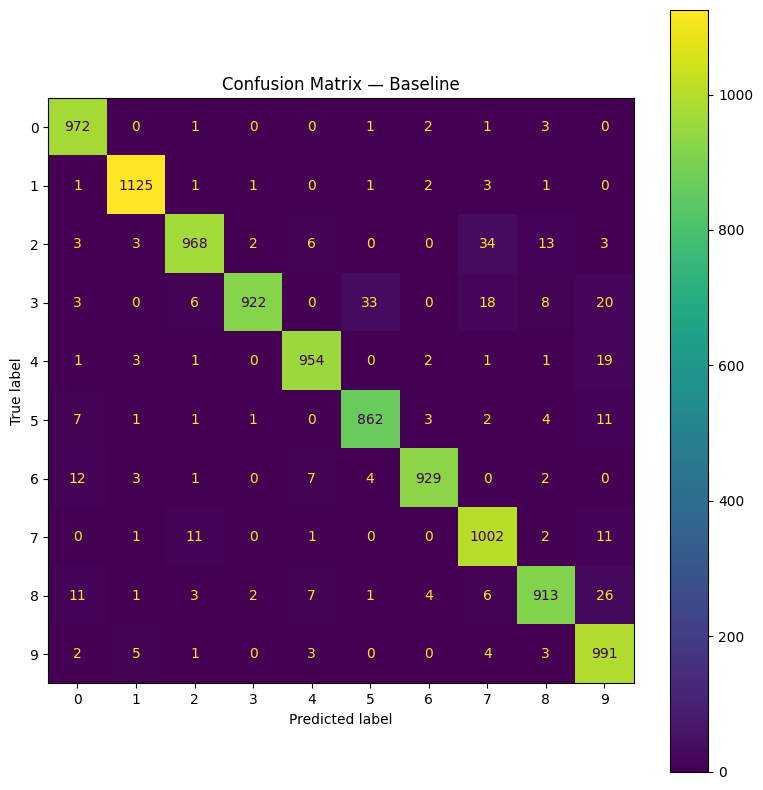

Validation-selected model: Baseline
Most frequent confusion: true 2 predicted as 7 (34 cases)


In [12]:
selected_model_name = highest_val_model
selected_model = models_to_compare[selected_model_name]

y_prob = selected_model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(ax=ax, values_format="d")
ax.set_title(f"Confusion Matrix — {selected_model_name}")
plt.tight_layout()
plt.show()

# Most frequent off-diagonal confusion
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
true_digit, predicted_digit = np.unravel_index(np.argmax(cm_off), cm_off.shape)
most_common_error = int(cm_off[true_digit, predicted_digit])

print("Validation-selected model:", selected_model_name)
print(
    f"Most frequent confusion: true {true_digit} predicted as "
    f"{predicted_digit} ({most_common_error} cases)"
)

## 13. Questions for Analysis

The answers below combine the theoretical concepts requested by the worksheet with the **actual values produced by this run**.


In [13]:
# @title
baseline_row = results_df[results_df["Model"] == "Baseline"].iloc[0]
regularized_df = results_df[results_df["Model"] != "Baseline"].copy()

# Use validation performance to identify the strongest regularized model for the comparison.
best_reg_idx = regularized_df["Best Validation Accuracy"].idxmax()
best_reg_row = results_df.loc[best_reg_idx]

baseline_gap_abs = abs(float(baseline_row["Generalization Gap"]))
regularized_gap_abs = abs(float(best_reg_row["Generalization Gap"]))

improved_val = (
    float(best_reg_row["Best Validation Accuracy"])
    > float(baseline_row["Best Validation Accuracy"])
)
improved_test = (
    float(best_reg_row["Test Accuracy"])
    > float(baseline_row["Test Accuracy"])
)
reduced_gap = regularized_gap_abs < baseline_gap_abs

if improved_val and improved_test and reduced_gap:
    q6_conclusion = (
        "Yes. In this run, the strongest regularized model improved validation "
        "and test accuracy while also reducing the absolute generalization gap."
    )
elif (improved_val or improved_test) and reduced_gap:
    q6_conclusion = (
        "Regularization provided partial evidence of improved generalization in this run. "
        "The strongest regularized model reduced the absolute generalization gap and "
        "improved at least one unseen-data accuracy measure, although not every metric improved."
    )
elif improved_val or improved_test:
    q6_conclusion = (
        "The evidence is mixed. A regularized model improved at least one unseen-data "
        "accuracy measure, but the generalization gap was not reduced."
    )
elif reduced_gap:
    q6_conclusion = (
        "Regularization reduced the absolute generalization gap, but it did not improve "
        "validation or test accuracy in this run. Therefore, the evidence is mixed rather "
        "than a clear performance improvement."
    )
else:
    q6_conclusion = (
        "No clear improvement was observed in this run. The regularized models did not "
        "outperform the baseline on the main unseen-data measures or reduce the "
        "generalization gap."
    )

answers = f'''
### 1. What is overfitting? Describe one sign of overfitting visible in a training curve.

**Answer:** Overfitting occurs when a model learns the training examples too closely, including details that do not generalize well to unseen data. A common visible sign is that training accuracy continues to increase while validation accuracy stops improving, or training loss continues to decrease while validation loss starts increasing.

### 2. Why can a model have high training accuracy but lower validation accuracy?

**Answer:** The model is optimized directly on the training set, so it can learn training-specific patterns or noise. Validation data are unseen during weight updates. A large training-validation difference therefore suggests that some learned patterns do not transfer well to new examples.

### 3. What does dropout do during training? Is dropout normally active during inference?

**Answer:** Dropout randomly deactivates a fraction of eligible activations during training, which reduces excessive dependence on particular units. It is normally disabled during inference.

### 4. How does data augmentation create more variation without collecting new original images?

**Answer:** Data augmentation applies label-preserving transformations to existing training images. In this experiment, small random translations move a digit slightly while keeping its class unchanged. This exposes the CNN to additional spatial variation without collecting new handwritten digits.

### 5. Why should the test set be kept separate from training and model selection?

**Answer:** The test set is intended to estimate final performance on data that did not influence training or model selection. Repeatedly tuning a model using test results would leak information from the test set into the development process and could produce an overly optimistic estimate of generalization.

### 6. Did regularization improve the results in your experiment? Support your answer with your recorded values.

**Answer:** {q6_conclusion}

Baseline — best validation accuracy: **{baseline_row["Best Validation Accuracy"]:.4f}**, test accuracy: **{baseline_row["Test Accuracy"]:.4f}**, generalization gap: **{baseline_row["Generalization Gap"]:+.4f}**.

Best validation-selected regularized model ({best_reg_row["Model"]}) — best validation accuracy: **{best_reg_row["Best Validation Accuracy"]:.4f}**, test accuracy: **{best_reg_row["Test Accuracy"]:.4f}**, generalization gap: **{best_reg_row["Generalization Gap"]:+.4f}**.
'''

display(Markdown(answers))


### 1. What is overfitting? Describe one sign of overfitting visible in a training curve.

**Answer:** Overfitting occurs when a model learns the training examples too closely, including details that do not generalize well to unseen data. A common visible sign is that training accuracy continues to increase while validation accuracy stops improving, or training loss continues to decrease while validation loss starts increasing.

### 2. Why can a model have high training accuracy but lower validation accuracy?

**Answer:** The model is optimized directly on the training set, so it can learn training-specific patterns or noise. Validation data are unseen during weight updates. A large training-validation difference therefore suggests that some learned patterns do not transfer well to new examples.

### 3. What does dropout do during training? Is dropout normally active during inference?

**Answer:** Dropout randomly deactivates a fraction of eligible activations during training, which reduces excessive dependence on particular units. It is normally disabled during inference.

### 4. How does data augmentation create more variation without collecting new original images?

**Answer:** Data augmentation applies label-preserving transformations to existing training images. In this experiment, small random translations move a digit slightly while keeping its class unchanged. This exposes the CNN to additional spatial variation without collecting new handwritten digits.

### 5. Why should the test set be kept separate from training and model selection?

**Answer:** The test set is intended to estimate final performance on data that did not influence training or model selection. Repeatedly tuning a model using test results would leak information from the test set into the development process and could produce an overly optimistic estimate of generalization.

### 6. Did regularization improve the results in your experiment? Support your answer with your recorded values.

**Answer:** Regularization provided partial evidence of improved generalization in this run. The strongest regularized model reduced the absolute generalization gap and improved at least one unseen-data accuracy measure, although not every metric improved.

Baseline — best validation accuracy: **0.9770**, test accuracy: **0.9638**, generalization gap: **+0.0190**.

Best validation-selected regularized model (Dropout) — best validation accuracy: **0.9750**, test accuracy: **0.9691**, generalization gap: **+0.0027**.


## 14. Optional Extension — Early Stopping

A fresh Dropout model is trained for up to **20 epochs**.

`EarlyStopping` monitors validation loss:
- `patience=2`: training may stop after two epochs without meaningful improvement.
- `restore_best_weights=True`: the model returns to the weights from the best validation-loss point.

This prevents unnecessary training after validation performance stops improving.


In [14]:
early_stop_model = build_cnn(dropout_rate=0.4)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

early_history = early_stop_model.fit(
    x_train_small,
    y_train_small,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

epochs_completed = len(early_history.history["loss"])
best_validation_loss = float(min(early_history.history["val_loss"]))
best_validation_epoch = int(np.argmin(early_history.history["val_loss"]) + 1)

early_test_loss, early_test_accuracy = early_stop_model.evaluate(
    x_test, y_test, verbose=0
)

print("Epochs completed:", epochs_completed)
print("Best validation loss:", f"{best_validation_loss:.4f}")
print("Best validation-loss epoch:", best_validation_epoch)
print("Early-stopping test accuracy:", f"{early_test_accuracy:.4f}")
print("Early-stopping test loss:", f"{early_test_loss:.4f}")

Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.6113 - loss: 1.2602 - val_accuracy: 0.8680 - val_loss: 0.4600
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8843 - loss: 0.3980 - val_accuracy: 0.9370 - val_loss: 0.2112
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9303 - loss: 0.2468 - val_accuracy: 0.9520 - val_loss: 0.1561
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9493 - loss: 0.1785 - val_accuracy: 0.9620 - val_loss: 0.1265
Epoch 5/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9563 - loss: 0.1479 - val_accuracy: 0.9650 - val_loss: 0.1077
Epoch 6/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9677 - loss: 0.1191 - val_accuracy: 0.9690 - val_loss: 0.0981
Epoch 7/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9673 - loss: 0.1062 - val_accuracy: 0.9690 - val_loss: 0.0983
Epoch 8/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9737 - loss: 0.0896 - val_accuracy: 0.9670 - v

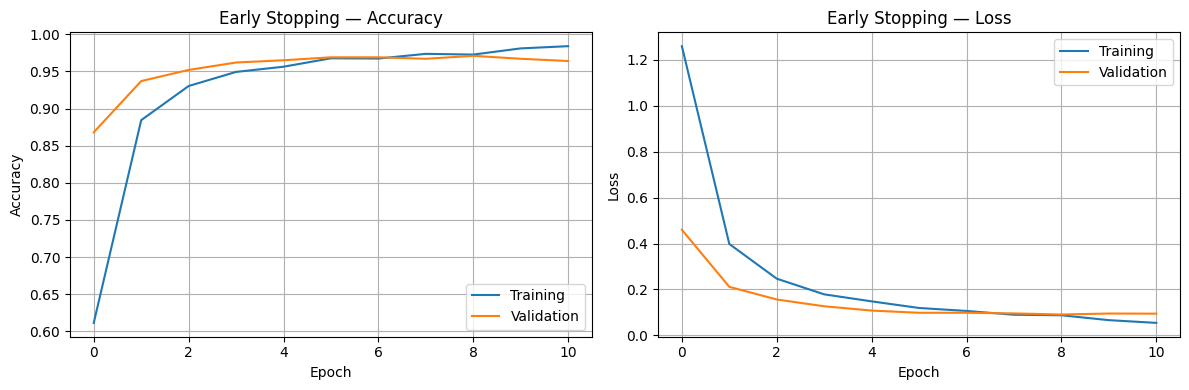

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(early_history.history["accuracy"], label="Training")
axes[0].plot(early_history.history["val_accuracy"], label="Validation")
axes[0].set_title("Early Stopping — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(early_history.history["loss"], label="Training")
axes[1].plot(early_history.history["val_loss"], label="Validation")
axes[1].set_title("Early Stopping — Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [16]:
# @title
early_stopping_interpretation = f'''
### Early Stopping Interpretation

The model completed **{epochs_completed} epoch(s)** out of a maximum of 20.

The lowest validation loss was **{best_validation_loss:.4f}**, reached at epoch **{best_validation_epoch}**.

Because `restore_best_weights=True`, the final model uses the weights associated with the best monitored validation-loss state rather than simply keeping the weights from the last executed epoch.

Its final test accuracy was **{early_test_accuracy:.4f}**.
'''

display(Markdown(early_stopping_interpretation))


### Early Stopping Interpretation

The model completed **11 epoch(s)** out of a maximum of 20.

The lowest validation loss was **0.0906**, reached at epoch **9**.

Because `restore_best_weights=True`, the final model uses the weights associated with the best monitored validation-loss state rather than simply keeping the weights from the last executed epoch.

Its final test accuracy was **0.9665**.


## 15. Final Discussion and Conclusion

This section is generated from the experimental results rather than from a predetermined expectation.


In [17]:
# @title
best_val_row = results_df.loc[
    results_df["Best Validation Accuracy"].idxmax()
]
best_test_row = results_df.loc[
    results_df["Test Accuracy"].idxmax()
]
best_gap_row = results_df.iloc[
    results_df["Generalization Gap"].abs().argmin()
]

final_text = f'''
### Final Discussion

- **Highest final training accuracy:** {highest_train_model}
- **Highest best validation accuracy:** {best_val_row["Model"]} ({best_val_row["Best Validation Accuracy"]:.4f})
- **Highest test accuracy:** {best_test_row["Model"]} ({best_test_row["Test Accuracy"]:.4f})
- **Smallest absolute generalization gap:** {best_gap_row["Model"]} ({best_gap_row["Generalization Gap"]:+.4f})

The results show why training accuracy should not be interpreted alone. The strongest training-set performer is not necessarily the model that generalizes best to validation and test data.

Regularization should therefore be evaluated empirically by considering validation behavior, test performance, learning curves, and the training-validation gap together.

### Conclusion

This experiment compared a baseline CNN with two regularized alternatives on MNIST under the same main architecture and training protocol. Dropout was used to reduce excessive dependence on individual activations, while data augmentation introduced small spatial variations. Early stopping provided an additional validation-based mechanism for limiting unnecessary training.

The experiment demonstrates that the effect of regularization must be judged from actual unseen-data performance rather than assumed in advance. The recorded values above provide the evidence for the final conclusion of this run.
'''

display(Markdown(final_text))


### Final Discussion

- **Highest final training accuracy:** Baseline
- **Highest best validation accuracy:** Baseline (0.9770)
- **Highest test accuracy:** Augmentation + Dropout (0.9709)
- **Smallest absolute generalization gap:** Dropout (+0.0027)

The results show why training accuracy should not be interpreted alone. The strongest training-set performer is not necessarily the model that generalizes best to validation and test data.

Regularization should therefore be evaluated empirically by considering validation behavior, test performance, learning curves, and the training-validation gap together.

### Conclusion

This experiment compared a baseline CNN with two regularized alternatives on MNIST under the same main architecture and training protocol. Dropout was used to reduce excessive dependence on individual activations, while data augmentation introduced small spatial variations. Early stopping provided an additional validation-based mechanism for limiting unnecessary training.

The experiment demonstrates that the effect of regularization must be judged from actual unseen-data performance rather than assumed in advance. The recorded values above provide the evidence for the final conclusion of this run.


## 16. Reproducibility Notes

- Random seed: **42**
- Main training epochs: **10**
- Batch size: **64**
- Training subset: **3,000 MNIST images**
- Validation subset: **1,000 MNIST images**
- Test set: **10,000 MNIST images**
- Dropout rate: **0.4**
- Random translation: **0.05 horizontal and 0.05 vertical**
- Optimizer: **Adam**
- Loss: **Sparse Categorical Cross-Entropy**

Numerical results may vary slightly across TensorFlow versions, hardware, and execution environments despite fixed seeds.
